In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Importamos las funciones ETL
from etl.extract import generar_datos_crudos
from etl.transform import calcular_kpis_calidad, aplicar_gobierno_y_calidad

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("✅ Librerías y módulos de ETL cargados correctamente.")

✅ Librerías y módulos de ETL cargados correctamente.


In [2]:
# 1. Generamos los datos crudos (El Mockup con errores intencionales)
df_crudo = generar_datos_crudos(15000)

# 2. Calculamos la calidad ANTES de la transformación
tcr_antes, ted_antes, tdr_antes = calcular_kpis_calidad(df_crudo)

# 3. Aplicamos el Gobierno de Datos (Transformación)
df_limpio, df_rechazos, df_bitacora = aplicar_gobierno_y_calidad(df_crudo)

# 4. Calculamos la calidad DESPUÉS de la transformación
tcr_despues, ted_despues, tdr_despues = calcular_kpis_calidad(df_limpio)

print("✅ Datos procesados. Listos para graficar.")

📥 [EXTRACT] Generando datos crudos (V0 - Inmutable) con Distribución Sigmoide...
✅ Datos procesados. Listos para graficar.


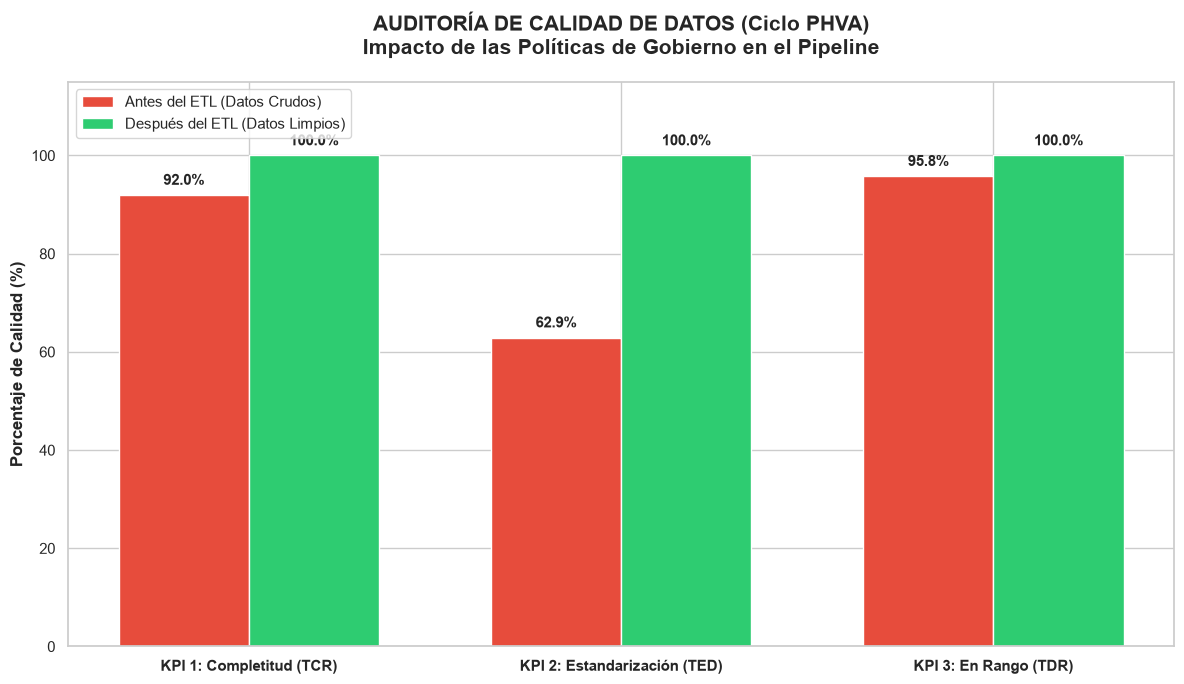

In [3]:
# Preparamos los datos para el gráfico
kpis = ['KPI 1: Completitud (TCR)', 'KPI 2: Estandarización (TED)', 'KPI 3: En Rango (TDR)']
valores_antes = [tcr_antes, ted_antes, tdr_antes]
valores_despues = [tcr_despues, ted_despues, tdr_despues]

x = range(len(kpis))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 7))

# Dibujamos las barras
barras_antes = ax.bar([i - width/2 for i in x], valores_antes, width, label='Antes del ETL (Datos Crudos)', color='#e74c3c')
barras_despues = ax.bar([i + width/2 for i in x], valores_despues, width, label='Después del ETL (Datos Limpios)', color='#2ecc71')

# Configuramos el diseño
ax.set_ylabel('Porcentaje de Calidad (%)', fontsize=12, fontweight='bold')
ax.set_title('AUDITORÍA DE CALIDAD DE DATOS (Ciclo PHVA)\nImpacto de las Políticas de Gobierno en el Pipeline', fontsize=15, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(kpis, fontsize=11, fontweight='bold')
ax.set_ylim(0, 115)
ax.legend(loc='upper left', fontsize=11)

# Añadimos las etiquetas de porcentaje sobre las barras
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 5),  # 5 puntos de separación vertical
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=11, fontweight='bold')

autolabel(barras_antes)
autolabel(barras_despues)

plt.tight_layout()
plt.show()

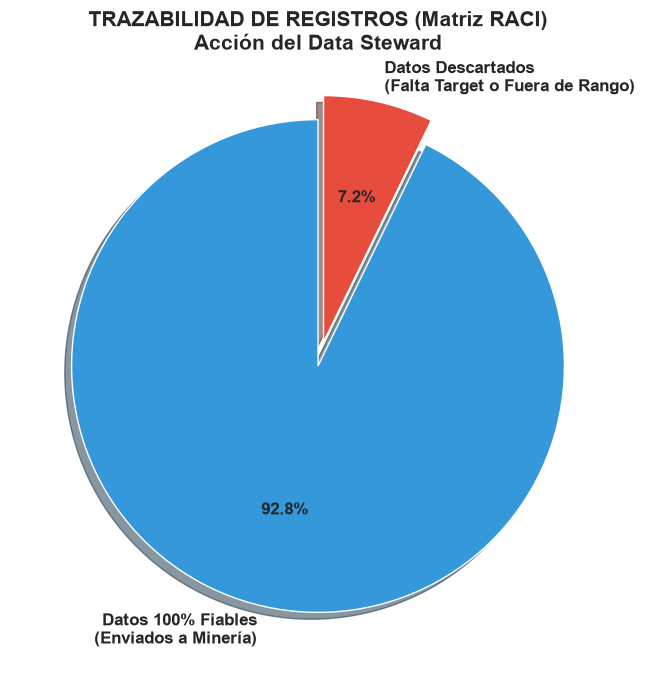

📝 RESUMEN DE AUDITORÍA:
Total de registros procesados: 15000
Registros aptos para Machine Learning: 13919
Registros enviados a cuarentena (staging_rechazos): 1081


In [4]:
# Datos para el gráfico de pastel
etiquetas = ['Datos 100% Fiables\n(Enviados a Minería)', 'Datos Descartados\n(Falta Target o Fuera de Rango)']
valores = [len(df_limpio), len(df_rechazos)]
colores = ['#3498db', '#e74c3c']
explode = (0, 0.1)  # Resaltar los rechazados

plt.figure(figsize=(8, 8))
plt.pie(valores, explode=explode, labels=etiquetas, colors=colores, autopct='%1.1f%%', 
        shadow=True, startangle=90, textprops={'fontsize': 12, 'fontweight': 'bold'})
plt.title('TRAZABILIDAD DE REGISTROS (Matriz RACI)\nAcción del Data Steward', fontsize=15, fontweight='bold')
plt.show()

print(f"📝 RESUMEN DE AUDITORÍA:")
print(f"Total de registros procesados: {len(df_crudo)}")
print(f"Registros aptos para Machine Learning: {len(df_limpio)}")
print(f"Registros enviados a cuarentena (staging_rechazos): {len(df_rechazos)}")

In [5]:
# Mostrar los primeros 10 registros que fueron rechazados por el Data Steward
print("🚫 MUESTRA DE DATOS RECHAZADOS (Cuarentena):")
display(df_rechazos[['id_producto_tienda_semana', 'ventas_unidades', 'quiebre_stock']].head(10))

🚫 MUESTRA DE DATOS RECHAZADOS (Cuarentena):


,id_producto_tienda_semana,ventas_unidades,quiebre_stock
7,REG-00008,120,NaN
22,REG-00023,500,1.0
29,REG-00030,56,NaN
62,REG-00063,300,1.0
82,REG-00083,300,1.0
101,REG-00102,103,NaN
122,REG-00123,21,NaN
141,REG-00142,76,NaN
144,REG-00145,300,0.0
181,REG-00182,70,NaN


In [6]:
# Requisito 2: Bitácora de incidencias registradas con causa, tratamiento y responsable.
print("📋 BITÁCORA DE INCIDENCIAS Y GOBIERNO DE DATOS (Matriz RACI):")
display(df_bitacora)

📋 BITÁCORA DE INCIDENCIAS Y GOBIERNO DE DATOS (Matriz RACI):


,Incidencia,Causa,Tratamiento,Responsable
0,463 registros con Target Nulo,Falta de consolidación POS/WMS,Descarte (Aislamiento),Custodio TI
1,631 registros con Ventas fuera de rango,Error de digitación en sucursal,Descarte (Aislamiento),Data Steward
2,5563 registros con ruido tipográfico,Falta de validación en E-commerce,Homologación (A+B=C),Data Steward


In [7]:
# Requisito 5: Pruebas (al menos una prueba válida y una inválida del control).
print("🧪 PRUEBA DE AUDITORÍA EN VIVO (MOCKUP)")
print("Inyectando 2 registros creados manualmente: Uno perfecto y uno con errores críticos...\n")

# Creamos un Mockup que NO viene de la base de datos
datos_prueba = pd.DataFrame({
    'id_producto_tienda_semana': ['TEST-01', 'TEST-02'],
    'tipo_promocion': ['2x1', '2X1'],           # Válido vs Ruido tipográfico
    'ventas_unidades': [150, -50],              # Válido vs Fuera de rango (Negativo)
    'quiebre_stock': [1, None],                 # Válido vs Nulo
    'canal_venta': ['Web', None]                # Válido vs Nulo
})

print("1️⃣ DATOS DE ENTRADA (Mockup):")
display(datos_prueba)

# Pasamos el Mockup por nuestro validador programado
prueba_limpia, prueba_rechazada, prueba_bitacora = aplicar_gobierno_y_calidad(datos_prueba)

print("\n2️⃣ RESULTADO DEL VALIDADOR:")
print(f"➤ Registros que PASARON el control (Válidos): {len(prueba_limpia)}")
display(prueba_limpia)

print(f"\n➤ Registros que NO PASARON el control (Inválidos/Rechazados): {len(prueba_rechazada)}")
display(prueba_rechazada)

print("\n💡 CONCLUSIÓN DE LA PRUEBA:")
print("El validador funcionó perfectamente. El registro TEST-01 pasó intacto.")
print("El registro TEST-02 fue rechazado porque, aunque el Data Steward pudo arreglar la promoción '2X1',")
print("la política de calidad prohíbe procesar ventas negativas (-50) y targets nulos.")

🧪 PRUEBA DE AUDITORÍA EN VIVO (MOCKUP)
Inyectando 2 registros creados manualmente: Uno perfecto y uno con errores críticos...

1️⃣ DATOS DE ENTRADA (Mockup):


,id_producto_tienda_semana,tipo_promocion,ventas_unidades,quiebre_stock,canal_venta
0,TEST-01,2x1,150,1.0,Web
1,TEST-02,2X1,-50,NaN,NaN



2️⃣ RESULTADO DEL VALIDADOR:
➤ Registros que PASARON el control (Válidos): 1


,id_producto_tienda_semana,tipo_promocion,ventas_unidades,quiebre_stock,canal_venta
0,TEST-01,2x1,150,1,Web



➤ Registros que NO PASARON el control (Inválidos/Rechazados): 1


,id_producto_tienda_semana,tipo_promocion,ventas_unidades,quiebre_stock,canal_venta
1,TEST-02,2x1,-50,NaN,Tienda



💡 CONCLUSIÓN DE LA PRUEBA:
El validador funcionó perfectamente. El registro TEST-01 pasó intacto.
El registro TEST-02 fue rechazado porque, aunque el Data Steward pudo arreglar la promoción '2X1',
la política de calidad prohíbe procesar ventas negativas (-50) y targets nulos.
